Regularization

In this notebook, I will try two common ways to reduce overfitting: dropout and weight decay. I will compare a baseline CNN with a regularized CNN while keeping the dataset split, data augmentation, and training setup the same.

The results may vary between runs. The goal is to make a fair comparison and understand the training/validation trends, not to guarantee a higher score.

1. Imports and setup

A GPU is recommended because this notebook trains two models on CIFAR-10.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

BATCH_SIZE = 128
EPOCHS = 6
NUM_WORKERS = 2

Device: cuda


2. Load CIFAR-10

Both models use the same training/validation split. I use random crops and horizontal flips for training only. Validation and test images are not randomly augmented.

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_full = datasets.CIFAR10(root="data", train=True, download=True, transform=train_transform)
eval_full = datasets.CIFAR10(root="data", train=True, download=True, transform=eval_transform)
test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=eval_transform)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_full), generator=generator).tolist()
train_indices, val_indices = indices[:45000], indices[45000:]

train_data = Subset(train_full, train_indices)
val_data = Subset(eval_full, val_indices)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available()
}
train_loader = DataLoader(train_data, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_data, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_data, shuffle=False, **loader_kwargs)

print(f"Train: {len(train_data)} | Validation: {len(val_data)} | Test: {len(test_data)}")

100%|██████████| 170M/170M [38:09<00:00, 74.5kB/s]


Train: 45000 | Validation: 5000 | Test: 10000


3. Define the two CNN versions

The baseline uses no dropout and no weight decay. The regularized model adds dropout in the classifier and uses weight decay in Adam. Everything else stays the same for a more useful comparison.

In [3]:
class CIFAR10CNN(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        classifier_layers = [
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU()
        ]
        if use_dropout:
            classifier_layers.append(nn.Dropout(p=0.4))
        classifier_layers.append(nn.Linear(128, 10))
        self.classifier = nn.Sequential(*classifier_layers)

    def forward(self, x):
        return self.classifier(self.features(x))

criterion = nn.CrossEntropyLoss()

4. Training and evaluation functions

I calculate average loss and accuracy across each full data split. Gradients are only enabled for the training phase.

In [4]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

5. Train the baseline model

This first run has no dropout and no weight decay. I keep the epoch count the same for both models.

In [5]:
baseline = CIFAR10CNN(use_dropout=False).to(device)
baseline_optimizer = torch.optim.Adam(baseline.parameters(), lr=0.001, weight_decay=0.0)

baseline_history = {
    "epoch": [], "train_loss": [], "train_accuracy": [],
    "val_loss": [], "val_accuracy": []
}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(baseline, train_loader, baseline_optimizer)
    val_loss, val_acc = run_epoch(baseline, val_loader)

    baseline_history["epoch"].append(epoch)
    baseline_history["train_loss"].append(train_loss)
    baseline_history["train_accuracy"].append(train_acc)
    baseline_history["val_loss"].append(val_loss)
    baseline_history["val_accuracy"].append(val_acc)

    print(f"Baseline | Epoch {epoch}/{EPOCHS} | train acc {train_acc:.2%} | val acc {val_acc:.2%} | val loss {val_loss:.4f}")

Baseline | Epoch 1/6 | train acc 40.07% | val acc 51.58% | val loss 1.3544
Baseline | Epoch 2/6 | train acc 54.35% | val acc 60.82% | val loss 1.0914
Baseline | Epoch 3/6 | train acc 60.87% | val acc 67.90% | val loss 0.9224
Baseline | Epoch 4/6 | train acc 65.41% | val acc 69.66% | val loss 0.8561
Baseline | Epoch 5/6 | train acc 68.27% | val acc 71.60% | val loss 0.8116
Baseline | Epoch 6/6 | train acc 70.69% | val acc 72.26% | val loss 0.7924


6. Train the regularized model

Dropout randomly disables some classifier activations during training. Weight decay penalizes large weights through the optimizer. These methods can reduce overfitting, although they may also reduce training accuracy and do not guarantee better validation accuracy.

In [6]:
regularized = CIFAR10CNN(use_dropout=True).to(device)
regularized_optimizer = torch.optim.Adam(
    regularized.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

regularized_history = {
    "epoch": [], "train_loss": [], "train_accuracy": [],
    "val_loss": [], "val_accuracy": []
}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(regularized, train_loader, regularized_optimizer)
    val_loss, val_acc = run_epoch(regularized, val_loader)

    regularized_history["epoch"].append(epoch)
    regularized_history["train_loss"].append(train_loss)
    regularized_history["train_accuracy"].append(train_acc)
    regularized_history["val_loss"].append(val_loss)
    regularized_history["val_accuracy"].append(val_acc)

    print(f"Regularized | Epoch {epoch}/{EPOCHS} | train acc {train_acc:.2%} | val acc {val_acc:.2%} | val loss {val_loss:.4f}")

Regularized | Epoch 1/6 | train acc 36.22% | val acc 48.78% | val loss 1.3964
Regularized | Epoch 2/6 | train acc 49.01% | val acc 57.24% | val loss 1.1747
Regularized | Epoch 3/6 | train acc 55.13% | val acc 61.80% | val loss 1.0486
Regularized | Epoch 4/6 | train acc 59.92% | val acc 65.92% | val loss 0.9585
Regularized | Epoch 5/6 | train acc 63.21% | val acc 69.40% | val loss 0.8619
Regularized | Epoch 6/6 | train acc 65.71% | val acc 68.84% | val loss 0.8730


7. Compare the learning curves

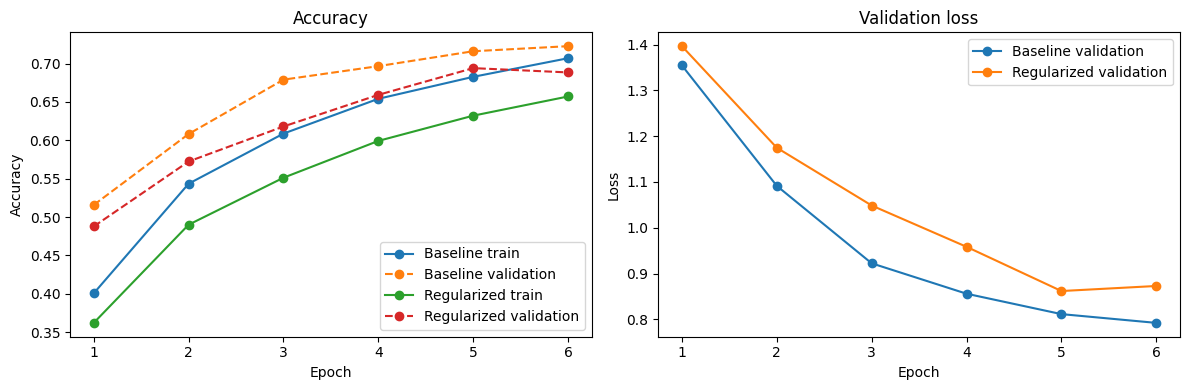

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(baseline_history["epoch"], baseline_history["train_accuracy"], marker="o", label="Baseline train")
axes[0].plot(baseline_history["epoch"], baseline_history["val_accuracy"], marker="o", linestyle="--", label="Baseline validation")
axes[0].plot(regularized_history["epoch"], regularized_history["train_accuracy"], marker="o", label="Regularized train")
axes[0].plot(regularized_history["epoch"], regularized_history["val_accuracy"], marker="o", linestyle="--", label="Regularized validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(baseline_history["epoch"], baseline_history["val_loss"], marker="o", label="Baseline validation")
axes[1].plot(regularized_history["epoch"], regularized_history["val_loss"], marker="o", label="Regularized validation")
axes[1].set_title("Validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

8. Compare the final validation results

In [8]:
comparison = pd.DataFrame([
    {
        "model": "Baseline",
        "final_train_accuracy": baseline_history["train_accuracy"][-1],
        "final_val_accuracy": baseline_history["val_accuracy"][-1],
        "final_val_loss": baseline_history["val_loss"][-1]
    },
    {
        "model": "Dropout + weight decay",
        "final_train_accuracy": regularized_history["train_accuracy"][-1],
        "final_val_accuracy": regularized_history["val_accuracy"][-1],
        "final_val_loss": regularized_history["val_loss"][-1]
    }
])
comparison

,model,final_train_accuracy,final_val_accuracy,final_val_loss
0,Baseline,0.706911,0.7226,0.792409
1,Dropout + weight decay,0.657089,0.6884,0.872963


9. Final test evaluation

I evaluate the regularized model on the test set only after the training comparison. The test set was not used to update model weights.

In [9]:
test_loss, test_accuracy = run_epoch(regularized, test_loader)
print(f"Regularized model test loss: {test_loss:.4f}")
print(f"Regularized model test accuracy: {test_accuracy:.2%}")

Regularized model test loss: 0.8819
Regularized model test accuracy: 68.96%
